# How early can you tell a Hacker News story will take off?

Target: the story is in the **top 30 of its UTC posting day** by score at 24 hours.
Features: only what is visible `t` minutes after posting. Evaluation: the **last two complete days
are held out**; nothing below is tuned on them.

This notebook does two things. First, at `t = 30`, it establishes honest baselines with confidence
intervals and calibration. Second, it repeats the experiment across `t` to draw the
observation-time curve: how prediction quality grows the longer you wait.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hn import dataset, evaluate, models

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
N_TRIALS = 60

## Data at t = 30 minutes

In [2]:
df30 = dataset.build(30)
train, test = dataset.temporal_split(df30)
cols = dataset.feature_columns(df30)
pd.DataFrame({
    "stories": [len(train), len(test)],
    "positives": [train.top30.sum(), test.top30.sum()],
    "days": [train.day.nunique(), test.day.nunique()],
}, index=["train", "test"])

,stories,positives,days
train,5266,148,5
test,2558,58,2


## Baselines

Three models of increasing complexity. The first is not a model at all: rank stories by their
raw score at 30 minutes. If the learned models cannot beat it clearly, the title, domain and
timing features are not adding much.

In [3]:
def fit_predict(model, train, test, cols):
    pipe = models.make_pipeline(model, cols)
    pipe.fit(train[cols], train.top30)
    return pipe, pipe.predict_proba(test[cols])[:, 1]

xgb_params = models.tune_xgb(train[cols], train.top30, cols, n_trials=N_TRIALS)
json.dump(xgb_params, open("xgb_params.json", "w"), indent=1)

preds = {
    "score only": test.log_score.values,
    "logistic": fit_predict(models.logistic(), train, test, cols)[1],
    "xgboost": fit_predict(models.xgb_classifier(models.pos_weight(train.top30), **xgb_params), train, test, cols)[1],
}
xgb_params

{'max_depth': 7,
 'min_child_weight': 6,
 'learning_rate': 0.01061765649934856,
 'n_estimators': 228,
 'subsample': 0.7303331276255287,
 'colsample_bytree': 0.7394273415279137,
 'gamma': 0.5906387125992586,
 'reg_lambda': 3.3003908811583416,
 'reg_alpha': 0.5354555897229341}

In [4]:
def fmt(ci): return f"{ci[0]:.3f} [{ci[1]:.3f}, {ci[2]:.3f}]"

rows = {}
for name, p in preds.items():
    s = evaluate.summary(test.top30, p, test.day)
    rows[name] = {"AUPRC [95% CI]": fmt(s["auprc"]), "AUROC [95% CI]": fmt(s["auroc"]),
                  "precision@30/day": round(s["precision@30/day"], 3), "Brier": round(s["brier"], 4)}
pd.DataFrame(rows).T

,AUPRC [95% CI],AUROC [95% CI],precision@30/day,Brier
score only,"0.341 [0.212, 0.465]","0.831 [0.770, 0.883]",0.367,NaN
logistic,"0.364 [0.238, 0.484]","0.869 [0.823, 0.910]",0.367,0.0841
xgboost,"0.295 [0.175, 0.435]","0.847 [0.794, 0.896]",0.383,0.0685


Random ranking would give AUPRC equal to the positive rate (about 0.023). The score-only baseline
gets most of the way to the learned models and every confidence interval overlaps; the tuned XGBoost
model is actually *below* the score-only baseline on the held-out days. Precision@30/day answers
the operational question: if a curator picked the 30 most promising stories each day at the
30-minute mark, what fraction would actually end up in the day's top 30? About 37%, for any of
the three.

## Calibration

Both learned models reweight the positive class (`class_weight="balanced"` for logistic,
`scale_pos_weight` for XGBoost), which inflates their probabilities by design. For picking a
top-k list only ranking matters, but the reliability curve shows that neither model's output can
be read as a probability without recalibration: a predicted 0.6 corresponds to roughly a 1-in-10
chance.

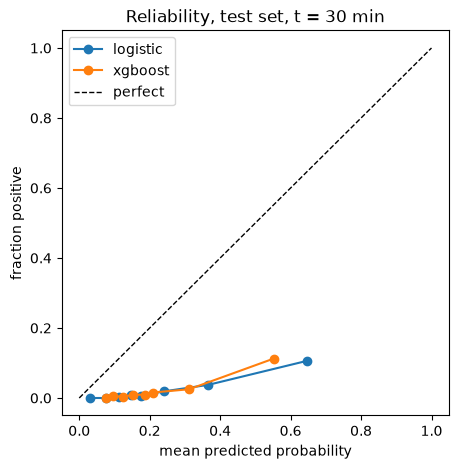

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
for name in ["logistic", "xgboost"]:
    cal = evaluate.calibration_table(test.top30, preds[name], bins=8)
    ax.plot(cal.mean_pred, cal.frac_pos, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set(xlabel="mean predicted probability", ylabel="fraction positive", title="Reliability, test set, t = 30 min")
ax.legend(); fig.savefig(FIG / "calibration_30m.png", dpi=120, bbox_inches="tight")

## Observation-time curve

Same split, same models, same XGBoost hyperparameters (tuned once at t = 30, not re-tuned per t).
Only the observation time changes.

In [6]:
TIMES = [10, 20, 30, 60, 90, 120, 180, 240, 360]
curve = []
for t in TIMES:
    df = dataset.build(t)
    tr, te = dataset.temporal_split(df)
    pt = {
        "score only": te.log_score.values,
        "logistic": fit_predict(models.logistic(), tr, te, cols)[1],
        "xgboost": fit_predict(models.xgb_classifier(models.pos_weight(tr.top30), **xgb_params), tr, te, cols)[1],
    }
    for name, p in pt.items():
        ap, lo, hi = evaluate.bootstrap_ci(te.top30, p)
        curve.append({"t_min": t, "model": name, "auprc": ap, "lo": lo, "hi": hi,
                      "p@30": evaluate.precision_at_k_daily(te.day, te.top30, p)})
curve = pd.DataFrame(curve)
curve.to_csv("observation_curve.csv", index=False)
curve.pivot(index="t_min", columns="model", values="auprc").round(3)

model,logistic,score only,xgboost
t_min,,,
10,0.141,0.093,0.063
20,0.235,0.203,0.141
30,0.364,0.341,0.295
60,0.567,0.559,0.513
90,0.677,0.680,0.587
120,0.731,0.736,0.639
180,0.815,0.825,0.791
240,0.843,0.849,0.784
360,0.904,0.914,0.897


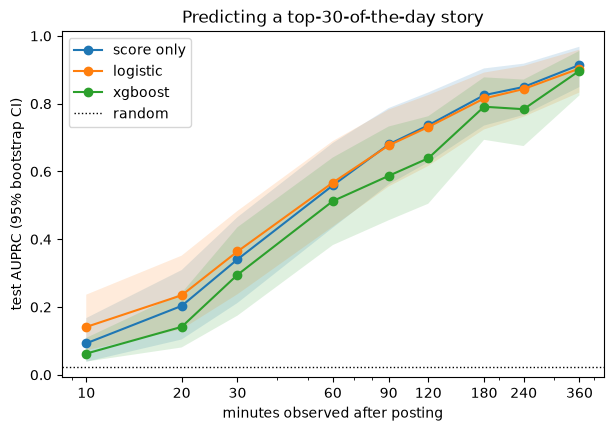

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, g in curve.groupby("model", sort=False):
    ax.plot(g.t_min, g.auprc, "o-", label=name)
    ax.fill_between(g.t_min, g.lo, g.hi, alpha=0.15)
ax.axhline(test.top30.mean(), color="k", ls=":", lw=1, label="random")
ax.set(xscale="log", xticks=TIMES, xticklabels=TIMES, xlabel="minutes observed after posting",
       ylabel="test AUPRC (95% bootstrap CI)", title="Predicting a top-30-of-the-day story")
ax.legend(); fig.savefig(FIG / "observation_curve.png", dpi=120, bbox_inches="tight")

## Reading the curve

- Prediction quality rises steeply over the first hour and keeps climbing more slowly after. AUPRC
  roughly doubles from 10 to 30 minutes and again from 30 to 90. By six hours a story has mostly
  either made the front page or not, and the "prediction" is close to a lookup.
- **Logistic regression beats tuned XGBoost at every observation time**, and the raw score alone
  is within the logistic model's confidence interval throughout. From 90 minutes on, the score
  alone is as good as any model. With about 150 positive training examples, a boosted ensemble has
  more capacity than the data can constrain; a regularized linear model does not.
- The gap between *score only* and *logistic* is the value of everything besides the current
  score: title n-grams, domain, posting hour, comment counts. It is largest early (t <= 30), when
  the score itself carries little information, and vanishes once the score has had time to
  separate the stories. Notebook 02 asks whether the *history* of the score helps more.
- Stories the collector had not fetched by `t` are excluded from each dataset (1.8% at 10 minutes,
  0.2% at 30). They are late discoveries, not late bloomers, and they finish in the top 30 at ten
  times the base rate, so a model would otherwise learn the collector's behavior.